# Assignment Task 2: Visualise Data Insights using Seaborn (15 marks)

### Import libraries and load data (1 mark)


In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("bidadari_resort_bookings.csv")
df.head()

,ID,Nationality,Age,DaysSinceCreation,arrival_date_year,arrival_date_month,AverageLeadTime,Revenue,OtherRevenue,BookingsCanceled,...,SRMediumFloor,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom
0,1.0,PRT,51.0,150.0,2016,July,45.0,371.0,105.3,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,PRT,NaN,1095.0,2016,July,61.0,280.0,53.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.0,FRA,60.0,1095.0,2016,July,93.0,240.0,60.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,6.0,JPN,54.0,1095.0,2016,July,58.0,230.0,24.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8.0,FRA,32.0,1095.0,2016,July,38.0,535.0,94.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


### Sub Task 1: Visualise Distribution of Revenue using Seaborn Histogram (1 mark)

Build a histogram of lodging revenue with Seaborn. Filter your data to rows where Revenue is less than 2000. 

<AxesSubplot:xlabel='Revenue', ylabel='Count'>

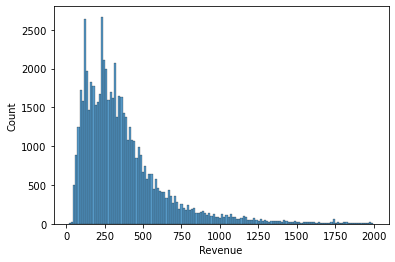

In [31]:
# all nationalities

sns.histplot(data=df.Revenue[df.Revenue < 2000])

<AxesSubplot:xlabel='Revenue', ylabel='Count'>

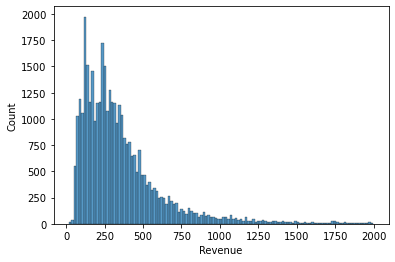

In [32]:
# selected 5 nationalities

sns.histplot(data=nations5.Revenue[nations5.Revenue < 2000])

### Sub Task 2: Create a Bar Chart (2 marks)

Create a horizontal bar chart plotting the average room nights stayed for selected 5 nationalities ("DEU", "FRA", "PRT", "GBR", "ESP"). Change the color palette to "husl".

In [37]:
# 5 nationalities  

nations = ["DEU", "FRA", "PRT", "GBR", "ESP"]


nations5 = df[df['Nationality'].isin(nations)]


averagenights = nations5.groupby('Nationality')['RoomNights'].mean().reset_index()
totalrevenue = nations5.groupby('Nationality')['Revenue'].mean().reset_index()

revnights = totalrevenue.join(averagenights.set_index('Nationality'), on='Nationality')
sortednights = revnights.sort_values(by=['Revenue'])
sortednights

,Nationality,Revenue,RoomNights
4,PRT,295.623772,2.557056
1,ESP,375.549448,2.763868
0,DEU,394.848770,3.336588
2,FRA,406.760875,3.305606
3,GBR,410.349476,3.171263


<AxesSubplot:xlabel='RoomNights', ylabel='Nationality'>

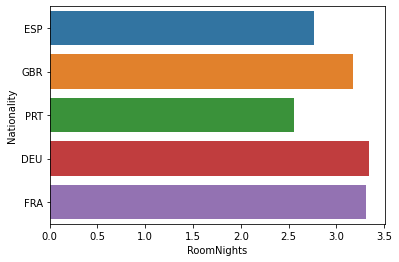

In [34]:
sns.barplot(x=sortednights.RoomNights, y=sortednights.Nationality)

### Sub Task 3: Create a Box Plot (1 mark)

Create a single boxplot of Revenue for the selected 5 countries, where nightly revenue is less than 2000.


In [6]:
nations5.columns

Index(['ID', 'Nationality', 'Age', 'DaysSinceCreation', 'arrival_date_year',
       'arrival_date_month', 'AverageLeadTime', 'Revenue', 'OtherRevenue',
       'BookingsCanceled', 'BookingsNoShowed', 'BookingsCheckedIn',
       'PersonsNights', 'RoomNights', 'DaysSinceLastStay',
       'DaysSinceFirstStay', 'DistributionChannel', 'MarketSegment',
       'SRHighFloor', 'SRLowFloor', 'SRAccessibleRoom', 'SRMediumFloor',
       'SRBathtub', 'SRShower', 'SRCrib', 'SRKingSizeBed', 'SRTwinBed',
       'SRNearElevator', 'SRAwayFromElevator', 'SRNoAlcoholInMiniBar',
       'SRQuietRoom'],
      dtype='object')

<AxesSubplot:xlabel='Revenue'>

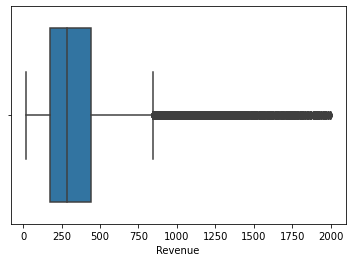

In [22]:
# 5 nations dataset

lessthan = nations5[nations5.Revenue < 2000].reset_index()
sns.boxplot(data=lessthan, x="Revenue")

### Sub Task 4: Create ViolinPlots ( 2 marks)

1. Create a chart that has one violinplot for each nationality. Look at these plots both without a filter and with  revenue filtered to less than 2000 and number of nights is less than 10 nights.
2. Create a violinplot for the age distribution for each of the selected 5 nationalities

In [8]:
# using dataset of 5 nationalities

lessthan2k = nations5['Revenue'] < 2000
nights10 = nations5['RoomNights'] < 10

countnations = nations5['Nationality'].value_counts().reset_index()

<AxesSubplot:xlabel='Nationality', ylabel='Revenue'>

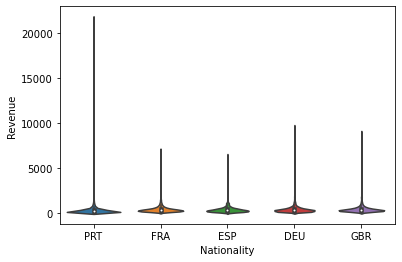

In [18]:
sns.violinplot(data=nations5, x="Nationality", y='Revenue')

C:\Users\zoe\AppData\Local\Temp/ipykernel_27628/1096364822.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  sns.violinplot(x="Nationality", y='Revenue', data=nations5[lessthan2k & nights10])


<AxesSubplot:xlabel='Nationality', ylabel='Revenue'>

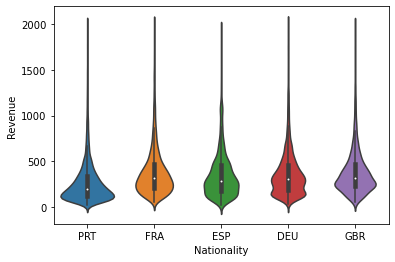

In [19]:
sns.violinplot(x="Nationality", y='Revenue', data=nations5[lessthan2k & nights10])

Age distribution for the 5 nations

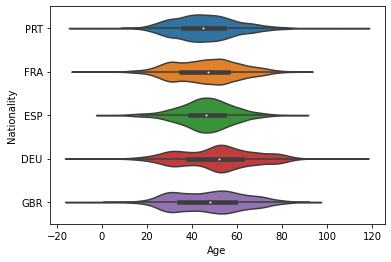

In [20]:
sns.violinplot(data=nations5, x="Age", y="Nationality")
plt.xlabel('Age')
plt.show()

### Sub Task 5: Linear Relationship Plots (2 marks)

1. Create a regression plot comparing Revenue as y and RoomNights as x for rows in 5 selected countries.
2. Modify the regresssion plot and use different colour line to represent the 5 nationalities. Which nationality appears to pay the most per night for customers with  revenue filtered is less than 2000 and number of nights is less than 10 nights ? Indicate your answer using Markdown cell.


<AxesSubplot:xlabel='Revenue', ylabel='RoomNights'>

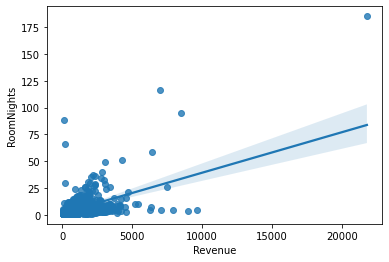

In [12]:
# 5 nations dataset

sns.regplot(data=nations5, x='Revenue', y='RoomNights')

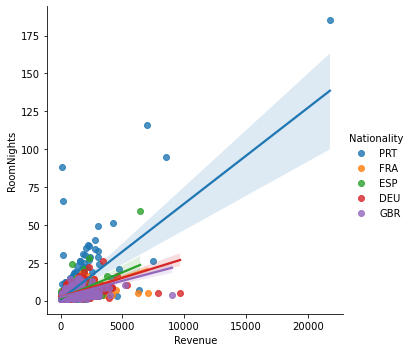

In [13]:
sns.lmplot(data=nations5, x='Revenue', y='RoomNights', hue='Nationality')

C:\Users\zoe\AppData\Local\Temp/ipykernel_27628/1079707913.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  filtered = nations5[lessthan2k | nights10].reset_index()


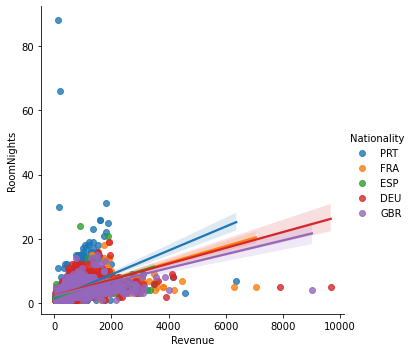

In [14]:
lessthan2k = df['Revenue'] < 2000
nights10 = df['RoomNights'] < 10

filtered = nations5[lessthan2k | nights10].reset_index()

sns.lmplot(data=filtered, x='Revenue', y='RoomNights', hue='Nationality')

After filtering, It is evident that GBR, Great Britian pay the most per night, as they have high revenue while having the lowest number of nights occupied.

### Sub Task 6: Create a Pairplot (2 marks)

Create a pairplot with the columns: Age, Revenue, OtherRevenue, PersonsNights, RoomNights and DaysSinceLastStay

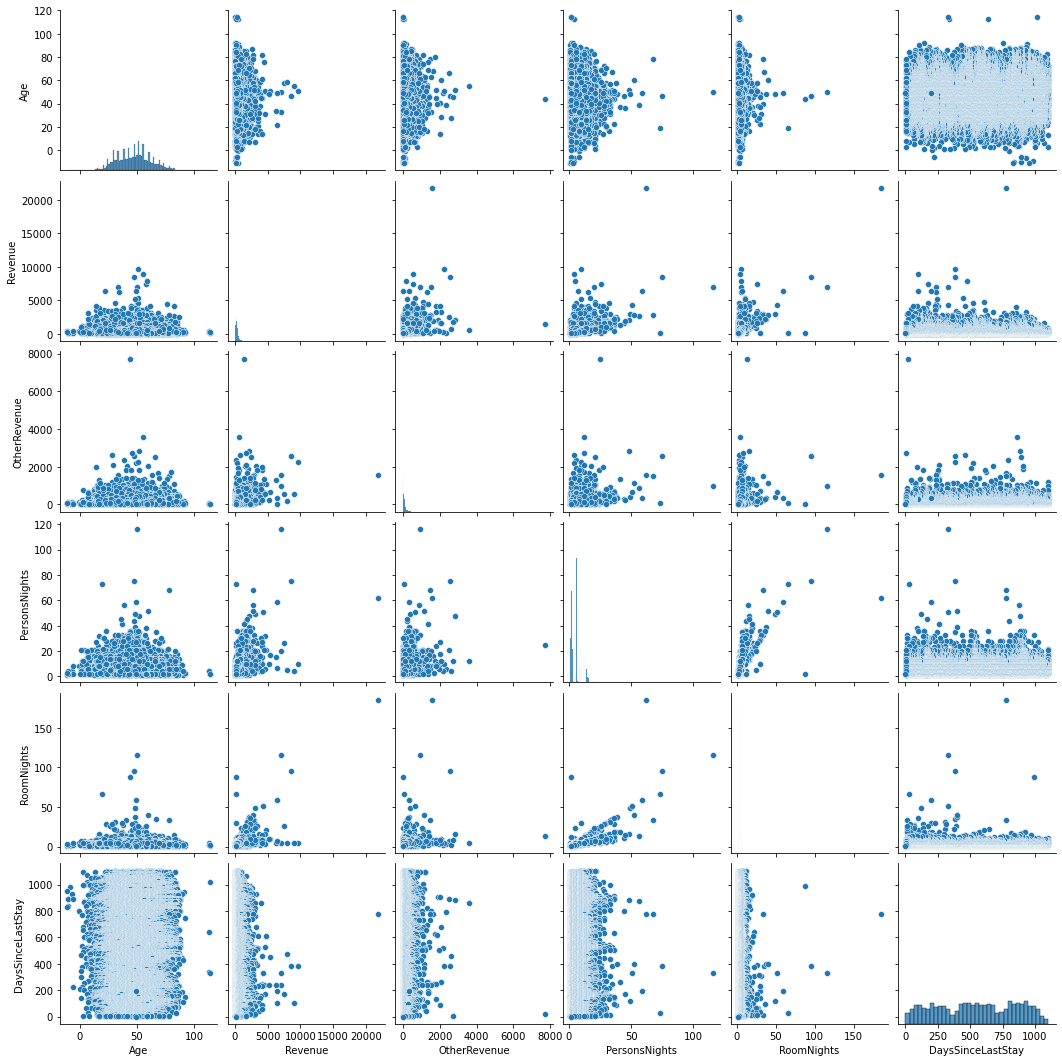

In [28]:
# using 5nations filter
 
paircols = ['Age', 'Revenue', 'OtherRevenue', 'PersonsNights', 'RoomNights' , 'DaysSinceLastStay']
pairplot = nations5[paircols]

sns.pairplot(pairplot)

### Sub Task 7: Create Heatmap (2 marks)

1. Using the 5 selected countries DataFrame, create a heatmap of Nationality as rows and MarketSegment as columns with the mean value of Revenue in each cell.
2. Create a heatmap of the correlation matrix created when using the .corr() method on the transactions dataframe. Use the 'vlag' color palette.

MarketSegment    Aviation  Complementary   Corporate      Direct      Groups  \
Nationality                                                                    
DEU            586.100000     248.026667  304.059259  530.722570  328.451998   
ESP            788.928571            NaN  256.745705  449.273282  330.612140   
FRA            679.466667     800.000000  303.486935  491.428898  280.640972   
GBR            319.044444     210.375000  490.454940  479.482608  476.164323   
PRT            444.192222     210.927586  303.846284  291.261709  249.149685   

MarketSegment       Other  Travel Agent/Operator  
Nationality                                       
DEU            449.245883             283.217904  
ESP            388.428656             292.256544  
FRA            463.912346             269.103578  
GBR            411.009234             306.080789  
PRT            331.806728             256.567935  


<AxesSubplot:xlabel='MarketSegment', ylabel='Nationality'>

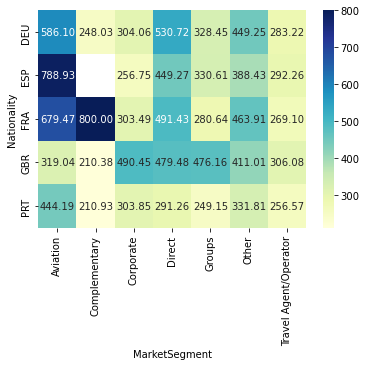

In [36]:
# 5 nations dataset

import numpy as np
maps = pd.pivot_table(nations5, index='Nationality', columns='MarketSegment', values='Revenue', aggfunc=np.mean)
print(maps)
sns.heatmap(maps, annot=True, fmt='.2f', cmap='YlGnBu')

C:\Users\zoe\AppData\Local\Temp/ipykernel_27628/2598846593.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  matrix = df.corr()


<AxesSubplot:>

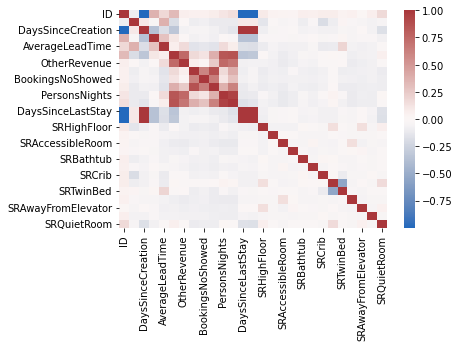

In [17]:
# using full dataset
matrix = df.corr()
sns.heatmap(matrix.corr(), cmap = 'vlag')

### Sub Task 8: Conclusion (2 marks)

Summarise your data exploratory task in one or 2 paragraph(s)


Looking at customers that are "DEU", "FRA", "PRT", "GBR", "ESP" (German, French, Portuguese, British, Spanish), 
German customers has the highest average room nights stayed, but British customers have the highest average revenue.
This is further proved in the regression plot as well. We can slightly increase the price for German customers to gain more revenue from the current customers, and target marketing towards Great Britian, to gain more British customers while maintaining their current pricing.

From the violin plot and pairplot, the median age of customers is 40 to 60 year old.
We can have more events to attract this age range to stay at the hotel, such as live bands, food or wine tasting that would appeal to 40 to 60 year olds.

From the heatmap, French customers mainly recieved room nights thorugh complementary means, or work in the aviation industry. Spanish and German customers also mainly work in the aviation industry.
This shows that a large portion of customers work in aviation, regardeless of nationality.
However, the factor with the lowest correlation to the five countries is Travel agent/operator. We can focus on attracting more travel agents by having a shuttle bus service to the airport or tourist spots. We can also hire staff who speak various languages, to allow for better communication with foreign customers.